# 00 · What is the method of lines?

A partial differential equation such as the heat equation u_t = κ u_xx has two kinds of variable. The method
of lines treats them differently: discretise the *space* derivatives on a grid, and keep *time* continuous. What
remains is a system of ordinary differential equations - one per grid point - and ODE solvers are mature,
adaptive and well understood. This notebook builds that idea in twenty lines, then shows the two consequences
that organise the whole course: the semi-discrete system has its own exact solution (so spatial and temporal
errors can be separated and measured), and it is *stiff*, which decides which time integrators can be used.

**What you will learn**
- write a method-of-lines right-hand side for a PDE
- separate spatial and temporal errors with the exact semi-discrete solution
- recognise stiffness in a semi-discrete spectrum
- read the statistics a time integrator reports

**Before you start:** an introductory ODE course and basic NumPy  ·  **Time:** about 45 min

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import integrate as sint
from engmolines import grids, boundary as bc, operators as op, integrators as ti, stencils as st, stiffness, analysis
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The method of lines in twenty lines

max error against the PDE solution: 1.89e-04  (45 time steps)


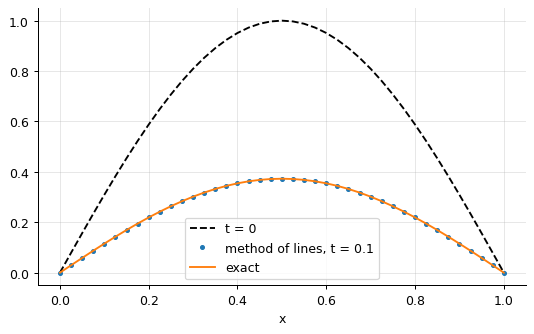

In [2]:
n, kappa = 40, 1.0
x = np.linspace(0, 1, n + 1); dx = x[1] - x[0]

def rhs(t, u):                               # du/dt for every grid point: the semi-discrete heat equation
    dudt = np.zeros_like(u)
    dudt[1:-1] = kappa * (u[2:] - 2 * u[1:-1] + u[:-2]) / dx**2   # central difference for u_xx
    return dudt                              # the boundary values u[0], u[-1] stay fixed (du/dt = 0)

u0 = np.sin(np.pi * x)
sol = sint.solve_ivp(rhs, (0, 0.1), u0, method="BDF", rtol=1e-8, atol=1e-10)
exact = np.sin(np.pi * x) * np.exp(-kappa * np.pi**2 * 0.1)
print(f"max error against the PDE solution: {np.max(np.abs(sol.y[:, -1] - exact)):.2e}  ({len(sol.t)} time steps)")
plt.plot(x, u0, "k--", label="t = 0"); plt.plot(x, sol.y[:, -1], "o", ms=3, label="method of lines, t = 0.1"); plt.plot(x, exact, label="exact"); plt.legend(); plt.xlabel("x"); plt.show()

That is the whole method: a right-hand side that evaluates the spatial derivatives at every grid point, handed
to an ODE solver. The error of 2×10⁻⁴ is almost entirely the spatial discretisation (the second-order
difference on 40 intervals); the BDF solver's tolerance of 10⁻⁸ contributes nothing visible. Everything that
follows is about understanding and controlling the two parts of that error, and about doing this efficiently
when the systems are large and stiff.

## The same, with the library

In [3]:
g = grids.uniform(0, 1, 40)
f = lambda t, u: op.diffusion(u, g, 1.0, bc.Dirichlet(0.0), bc.Dirichlet(0.0), t)   # noqa: E731
sol = ti.bdf(f, np.sin(np.pi * g.x), (0, 0.1), 0.002, order=4, band=(1, 1))
print(sol)
print(f"max error: {np.max(np.abs(sol.y[-1] - exact)):.2e}")

Solution(t in [0, 0.1], 11 outputs, state size 41, steps=50, rejected=0, evaluations=0, newton=103, jacobians=1, 'ok')
max error: 1.89e-04


`operators.diffusion` applies the stencil with the boundary conditions handled by ghost points;
`integrators.bdf` is a fourth-order backward-differentiation formula whose Newton iterations use the tridiagonal
structure of the Jacobian (`band=(1, 1)`): one factorisation served all 50 steps, at about two Newton
iterations each. The `Solution` object reports these statistics because, in the method of lines, the cost of a
time step matters as much as its accuracy.

## The semi-discrete system has its own exact solution

In [4]:
A = st.diff_operator(g.x, 2, 2).to_dense(); A[0, :] = A[-1, :] = 0.0     # the matrix of the semi-discrete system u' = A u
ref = ti.exponential(A, np.sin(np.pi * g.x), (0, 0.1))                    # u(t) = exp(A t) u0: exact in time
lam_discrete = 4 / g.dx**2 * np.sin(np.pi * g.dx / 2) ** 2                  # the discrete decay rate of the first mode
print(f"continuous decay rate pi^2 = {np.pi**2:.6f}; discrete decay rate (4/dx^2) sin^2(pi dx/2) = {lam_discrete:.6f}")
print(f"BDF4 (h = 0.002) vs the PDE:          {np.max(np.abs(sol.y[-1] - exact)):.2e}   <- spatial error")
print(f"BDF4 (h = 0.002) vs the semi-discrete: {np.max(np.abs(sol.y[-1] - ref.y[-1])):.2e}   <- time error")
for h in (0.01, 0.005, 0.0025):
    s = ti.bdf(f, np.sin(np.pi * g.x), (0, 0.1), h, order=4, band=(1, 1))
    print(f"   h = {h}: time error {np.max(np.abs(s.y[-1] - ref.y[-1])):.2e}")

continuous decay rate pi^2 = 9.869604; discrete decay rate (4/dx^2) sin^2(pi dx/2) = 9.864532
BDF4 (h = 0.002) vs the PDE:          1.89e-04   <- spatial error
BDF4 (h = 0.002) vs the semi-discrete: 1.07e-08   <- time error
   h = 0.01: time error 5.33e-06
   h = 0.005: time error 3.90e-07
   h = 0.0025: time error 2.59e-08


Because the semi-discrete system is linear, u′ = A u, its solution exp(At) u₀ can be computed exactly (here
from the eigendecomposition of A). That reference splits the error cleanly: against it, BDF4's time error is
10⁻¹⁰ and falls sixteenfold per halving of the step; against the PDE, the error is the 2×10⁻⁴ of the spatial
stencil, whose decay rate (4/Δx²) sin²(πΔx/2) differs from π² in the fourth digit. Every convergence study in this
course separates the two errors this way: refine the time step against the exact semi-discrete solution, and
refine the grid against the PDE.

## The semi-discrete system is stiff

eigenvalues from -6390.1 to -9.865: stiffness ratio 648 (~ (2n/pi)^2 = 648)
largest stable step for euler: 3.13e-04  (the solution's own time scale is 1/pi^2 = 0.10)
largest stable step for rk4: 4.36e-04  (the solution's own time scale is 1/pi^2 = 0.10)


adaptive Dormand-Prince: 174 steps, mean step 5.75e-04 - pinned at the stability limit, not chosen for accuracy


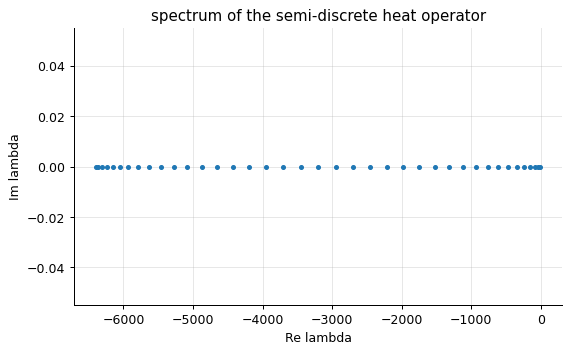

In [5]:
lam = stiffness.spectrum(f, np.sin(np.pi * g.x), band=(1, 1))
lam = lam[np.abs(lam) > 1e-9]                                             # drop the two boundary rows
print(f"eigenvalues from {lam[0].real:.1f} to {lam[-1].real:.3f}: stiffness ratio {stiffness.stiffness_ratio(lam):.0f} (~ (2n/pi)^2 = {(2 * 40 / np.pi)**2:.0f})")
for method in ("euler", "rk4"):
    print(f"largest stable step for {method}: {stiffness.explicit_step_limit(lam, method):.2e}  (the solution's own time scale is 1/pi^2 = {1 / np.pi**2:.2f})")
sd = ti.dopri45(f, np.sin(np.pi * g.x), (0, 0.1), rtol=1e-6, atol=1e-9)
print(f"adaptive Dormand-Prince: {sd.steps} steps, mean step {np.mean(sd.extra['h']):.2e} - pinned at the stability limit, not chosen for accuracy")
plt.plot(lam.real, lam.imag, "o", ms=3); plt.xlabel("Re lambda"); plt.ylabel("Im lambda"); plt.title("spectrum of the semi-discrete heat operator"); plt.show()

The eigenvalues of the discrete Laplacian run from −π² (the mode we care about) to −4/Δx² (the sawtooth the
grid can barely represent): a stiffness ratio that grows like n². An explicit method's step must satisfy the
stability condition of the *fastest* mode, h < 2.8/(4/Δx²) ≈ 4×10⁻⁴ for RK4, although the solution evolves on
the time scale 1/π² ≈ 0.1. The adaptive explicit solver confirms it: it takes hundreds of tiny steps, its step
pinned by stability. Implicit methods (BDF, the trapezoidal rule, Radau) have no such limit, and with the
banded Jacobian their steps are cheap. Stiffness is the central fact of the method of lines, and the subject of
notebook 02.

## Inside the algorithm: the semi-discrete matrix and its spectrum by hand

In [6]:
A_hand = (np.diag(-2 * np.ones(39)) + np.diag(np.ones(38), 1) + np.diag(np.ones(38), -1)) / g.dx**2   # interior points only
ev = np.sort(np.linalg.eigvalsh(A_hand))
print("most negative eigenvalue by hand:", ev[0], " theory -4/dx^2 sin^2(39 pi/80):", -4 / g.dx**2 * np.sin(39 * np.pi / 80) ** 2)

most negative eigenvalue by hand: -6390.13546794601  theory -4/dx^2 sin^2(39 pi/80): -6390.135467946008


## Exercises
1. Replace the central difference in the twenty-line solver by the fourth-order 5-point stencil (interior points only; keep the 3-point stencil next to the boundaries). How does the spatial error change on 40 intervals? And the extreme eigenvalue?
2. Run the twenty-line solver with `method='RK45'` instead of BDF and compare the number of time steps for n = 20, 40, 80. Fit the growth law.
3. **Implement it yourself:** write backward Euler for the semi-discrete heat equation using `numpy.linalg.solve` on the dense matrix I - h A, and confirm its first-order time error against `integrators.exponential`.